In [33]:
#__ Import: Numerical __
import numpy as np
from scipy.stats import gaussian_kde
from scipy.ndimage import gaussian_filter

#__ Import: Topophone2 __
from topophone2.utils.read import read_txt
from topophone2.inversion import MarginalStats
from topophone2.utils.math import density_params, harmonic2D_density, density_function

#__ Import: Plotting __
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1.anchored_artists import AnchoredSizeBar
import matplotlib.font_manager as fm
from matplotlib.colors import LinearSegmentedColormap
import matplotlib.tri as tri
import matplotlib.ticker as ticker
from matplotlib.gridspec import GridSpec
from matplotlib.lines import Line2D
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
import cmcrameri.cm as cmc
from matplotlib.patches import Patch, ConnectionPatch

#__ Set up: Plotting __
theme = ['#DC4424', '#74A466', '#24448C', '#F8BC5C']
small, large = 8, 10
plt.rcParams["font.sans-serif"] = ['Arial']
cmap0 = LinearSegmentedColormap.from_list("cmap0", ["white", theme[0]])

## Synthetic data

In [ ]:
#__ Read array geometry __
out = read_txt(f"./data/TRIAD_15DB/TRIAD_FULL_15DB_topophone2.txt")
x   = out[1]  # Receiver position [m] (receiver, direction)

#__ Load synthetic parameters __
sim_data = np.load('./data/SYNTHETICS.npz')

#__ Unpack: Signal __
slowness_T = sim_data['slowness_T']  # Horizontal slowness    [s.m-1]     (source, mode, direction)
energy_T   = sim_data['energy_T']    # Recorded energy        [uPa2.Hz-1] (source, mode)
xS_T       = sim_data['xS_T']        # Source location        [m]         (source, direction)
w_energy   = sim_data['w_energy']    # Relative source energy [uPa2.Hz-1] (source)

#__ Unpack: Noise __
slowness_J = sim_data['slowness_J']  # Horizontal slowness    [s.m-1]     (source, direction)
energy_J   = sim_data['energy_J']    # Recorded energy        [uPa2.Hz-1] (source)
az_J       = sim_data['az']          # Source azimuth         [deg]       (source)
s0_J       = sim_data['s0'][0]       # Noise slowness         [s.m-1]

#__ Unpack: Sound speed __
z   = sim_data['z']    # Depth [m] (depth,)
c_z = sim_data['c_z']  # Sound speed [m.s-1] (depth,)
sed_thick = 800.0
z_sed = np.linspace(z[-1], z[-1] + sed_thick, 9)
c_sed = np.linspace(1500., 2200., 9)
z_sed = np.append(z_sed, 10e3)
c_sed = np.append(c_sed, c_sed[-1])
z_max = 4.5e3  # Maximum depth [m]
zr    = 1.37e3  # Receiver depth [m]

#__ Estimate energy density __
slowness_T = slowness_T.reshape(-1, 2)
energy_T   = energy_T.reshape(-1)
good = (
    np.all(np.isfinite(slowness_T), axis=1)
    & np.isfinite(energy_T)
    & (energy_T > 1e-12*energy_T.max())
)
s_good = slowness_T[good]
w_good = energy_T[good]
sx, sy = s_good[:,0], s_good[:,1]
pad = 0.15 * max(np.ptp(sx), np.ptp(sy))
ex = np.linspace(sx.min()-pad, sx.max()+pad, 200+1)
ey = np.linspace(sy.min()-pad, sy.max()+pad, 200+1)
xc, yc = 0.5*(ex[1:] + ex[:-1]), 0.5*(ey[1:] + ey[:-1])
gx, gy = np.meshgrid(xc, yc, indexing='ij')
w_density, _, _ = np.histogram2d(sx, sy, bins=[ex, ey], weights=w_good)   # [x, y]
w_density /= np.diff(ex)[:,None] * np.diff(ey)[None,:]
w_density /= w_density.max()

#__ Unpack: True model __
m_true = sim_data['m_true']

#__ Read: Inversion results __
m     = np.load('./models/TRIAD_15DB/inversion_results.npz')['m']
w_T   = m[:,0]
xi    = m[:,1:3]
sigma = m[:,3:5]
corr  = m[:,5]
w_J   = m[:,6]
a     = m[:,7]
b     = m[:,8]

#__ Calculate SNR cumulative distribution __
snr_stats = MarginalStats((w_T-w_J)[:,None])
pcum_snr, pcum_snr_vec = snr_stats.probability_density(i=0, cumulative='reverse')

#__ Calculate backazimuth distribution __
_, _, xi_circ, _, sigma_circ, _ = density_params(xi, sigma, corr[:,None])
_, _, xi_circ_true, _, sigma_circ_true, _ = density_params(m_true[1:3][None,:], m_true[3:5][None,:], m_true[5][None,None])
stats_xi    = MarginalStats(xi_circ)
stats_sigma = MarginalStats(sigma_circ)
p_az, p_az_vec = stats_xi.probability_density(i=1)
p_bw, p_bw_vec = stats_sigma.probability_density(i=1)

#__ Calculate harmonic coefficient distributions __
stats = MarginalStats(m)
p_a, p_a_vec = stats.probability_density(i=7)
p_b, p_b_vec = stats.probability_density(i=8)

#__ Information gain __
ig = np.load('./data/figures/info-gain.npz')
rel_IG_rec = ig['rel_IG_rec']
rel_IG_noisy = ig['rel_IG_noisy']

#__ Noise field __
baz = np.linspace(0, 360, 360)
rho = harmonic2D_density(baz, a[:,None], b[:,None])
rho_true = harmonic2D_density(baz, m_true[7][None,None], m_true[8][None,None])

#__ Calculate density functions __
density = density_function((gx,gy), xi[:1000], sigma[:1000], corr[:1000,None])
density_true = density_function((gx,gy), m_true[1:3][None,:], m_true[3:5][None,:], m_true[5][None,None])
density /= np.max(density, axis=(1,2), keepdims=True)
density_true /= np.max(density_true, axis=(1,2), keepdims=True)

#__ Credible intervals __
snr_90, _ = snr_stats.credible_interval(80, [0])
baz_05, baz_95 = stats_xi.credible_interval(90, [1])
bw_05, bw_95 = stats_sigma.credible_interval(90, [1])

#__ Source-energy density __
z_hypo, alpha, f0 = 15.0e3, 0.02, 5.0
srcR, srcBz, srcRd = 600.0e3, 105.0, 60.0e3
src0 = srcR * np.array([np.sin(np.radians(srcBz)), np.cos(np.radians(srcBz))])
Xs, Ys = np.meshgrid(
    np.linspace(src0[0]-1.2*srcRd, src0[0]+1.2*srcRd, 300),
    np.linspace(src0[1]-1.2*srcRd, src0[1]+1.2*srcRd, 300),
    indexing='ij'
)
r_epi = np.hypot(Xs - src0[0], Ys - src0[1])
d_s   = np.sqrt((z_hypo - z_max)**2 + r_epi**2)
E_src = (10**(-alpha*(d_s/1e3)*f0/20) / d_s)**2 * (r_epi <= srcRd)
E_src /= E_src.max()

/tmp/ipykernel_2956/1575710012.py:309: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


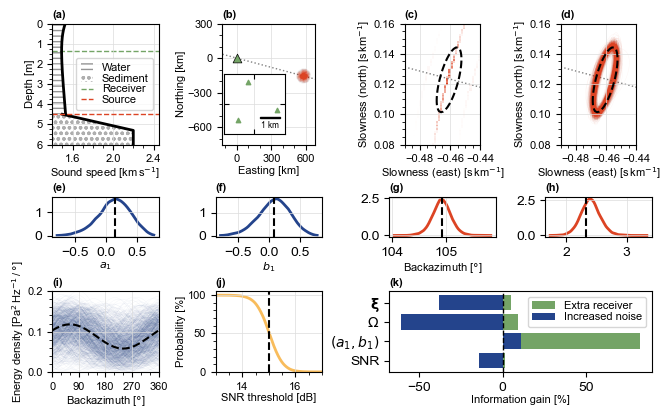

In [28]:
#________ CREATE FIGURE ________#

#__ Figure __
fig = plt.figure(
    figsize   = (6.5, 4.0),
    facecolor = 'white',
    layout    = 'constrained'
)

#__ Axes __
gs  = GridSpec(
    figure = fig,
    nrows  = 3,
    ncols  = 4,
    height_ratios=[3, 1, 2]
)
axs = [
    # First row
    fig.add_subplot(gs[0,0]), # axs[0] is the sound-speed profile
    fig.add_subplot(gs[0,1], aspect='equal'), # axs[1] is the source-receiver geometry
    fig.add_subplot(gs[0,2], aspect='equal'), # axs[2] is the real signal
    fig.add_subplot(gs[0,3], aspect='equal'), # axs[3] is the inverted signal 
    # Second row
    fig.add_subplot(gs[2,0]), # axs[4] is the noise field
    fig.add_subplot(gs[2,1]), # axs[5] is the NSR noise to signal ratio
    fig.add_subplot(gs[2,2:4]), # axs[6] is information gain
    # Third row
    fig.add_subplot(gs[1,0]), # axs[7] is the pdf a
    fig.add_subplot(gs[1,1]), # axs[8] is the pdf b
    fig.add_subplot(gs[1,2]), # axs[9] is the pdf backazimuth
    fig.add_subplot(gs[1,3]),  # axs[10] is the pdf of ?    
]

#__ Create inset axes __
#ax_in = axs[1].inset_axes([0.02, 0.02, 0.30, 0.30], zorder=5)
ax_in = axs[1].inset_axes([0.02, 0.01, 0.65, 0.65], zorder=5) # x0, y0, width, height]
ax_in.set_facecolor('white')
ax_in.set_aspect('equal')

#__ Labels __
for ax, xlab, ylab in zip(axs,
    [r"Sound speed [km$\,$s$^{-1}$]", r"Easting [km]", r"Slowness (east) [s$\,$km$^{-1}$]", r"Slowness (east) [s$\,$km$^{-1}$]",  r"Backazimuth [$\degree$]",  r"SNR threshold [dB]",r"Information gain [%]", r"$a_1$", r"$b_1$", r"Backazimuth [$\degree$]"],
    [r"Depth [m]", r"Northing [km]", r"Slowness (north) [s$\,$km$^{-1}$]", r"Slowness (north) [s$\,$km$^{-1}$]", r"Energy density [Pa$^2$$\,$Hz$^{-1}$$\,$/$\,\degree$]", r"Probability [%]", None, None, None, None]
):
    if (xlab is not None): ax.set_xlabel(xlab, fontsize=small, labelpad=1.0)
    if (ylab is not None): ax.set_ylabel(ylab, fontsize=small, labelpad=1.0)  
 
#__ Ticks __
for ax, xlims, ylims, xticks, yticks in zip(axs,
    #  sound speed   geometry      real signal     inverted signal  noise field  SNR\n",
   [(1.4,2.45),    (-125,680),  (-0.49,-0.44),  (-0.49,-0.44),   (0,360),     (13,17)],   # xlims\n",
   [(6.0,0.0),    (-750,300),   (0.08,0.16),    (0.08,0.16),     (0,0.2),     (0,105)],   # ylims\n",
   [(0.4,0.1),    (300,100),    (0.02,0.005),   (0.02,0.005),    (90,30),     (2,0.5)],   # xticks (major, minor)\n",
   [(1.0,0.25),   (300,100),    (0.02,0.005),   (0.02,0.005),    (0.1,0.02),  (50,10)]    # yticks (major, minor)\n",
):
    if (xlims is not None): ax.set_xlim(*xlims)
    if (ylims is not None): ax.set_ylim(*ylims)
    if (xticks is not None):
        ax.xaxis.set_major_locator(ticker.MultipleLocator(xticks[0]))
        ax.xaxis.set_minor_locator(ticker.MultipleLocator(xticks[1]))
    else: ax.set_xticks([])
    if (yticks is not None):
        ax.yaxis.set_major_locator(ticker.MultipleLocator(yticks[0]))
        ax.yaxis.set_minor_locator(ticker.MultipleLocator(yticks[1]))
    else: ax.set_yticks([])
    ax.tick_params(labelsize=small)
    ax.grid(color='gainsboro', linewidth=0.5)

#__ Ticks (inset) __
ax_in.set_xlim(-1.5,1.5)
ax_in.set_ylim(-1.5,1.5)
ax_in.set_xticks([0])
ax_in.set_yticks([0])
ax_in.tick_params(
    which='both', direction='in',
    top=True, right=True,
    labelbottom=False, labelleft=False
)
ax_in.grid(color='gainsboro', linewidth=0.5)

#__ Polar axis __
# axs[4].set_theta_zero_location('N')
# axs[4].set_theta_direction(-1)
# axs[4].tick_params(labelbottom=False, labelleft=False)

#________ PLOT: SOUND-SPEED PROFILE ________#

#__ Water column __
axs[0].fill_betweenx(
    1e-3*z, 0.0, 1e-3*c_z,
    facecolor='none', edgecolor='grey',
    hatch='---', linewidth=0.0, alpha=0.83, zorder=0
)
axs[0].plot(1e-3*c_z, 1e-3*z, color='k', linewidth=2.0, zorder=2, label="Water")

#__ Sediment column __
axs[0].fill_betweenx(
    1e-3*z_sed, 0.0, 1e-3*c_sed,
    facecolor='none', edgecolor='k',
    hatch='ooo', linewidth=0.0, alpha=0.3, zorder=0
)
axs[0].plot(1e-3*c_sed, 1e-3*z_sed, color='k', lw=2.0, zorder=2, label="Sediment")

#__ Receiver/source depths __
axs[0].axhline(1e-3*zr, ls='--', color=theme[1], lw=1.0, zorder=1)
axs[0].axhline(1e-3*z_max, ls='--', color=theme[0], lw=1.0, zorder=2)

#__ Legend __

ssp_handles = [
    Patch(facecolor='none', edgecolor='grey', hatch='---', alpha=0.83, linewidth=0.0),                       # Water
    Patch(facecolor='none', edgecolor='k', hatch='ooo', alpha=0.3, linewidth=0.0),                    # Sediment
    Line2D([], [], color=theme[1], ls='--', lw=1.0),           # Receiver depth
    Line2D([], [], color=theme[0], ls='--', lw=1.0),           # Source depth
]
ssp_labels = ["Water", "Sediment", "Receiver", "Source"]

axs[0].legend(
    ssp_handles, ssp_labels,
    fontsize=small, frameon=True, loc='center right', handlelength=1.1, labelspacing=0.08
)

#________ PLOT: SOURCE-RECEIVER GEOMETRY ________#

#__ Plot source energy __
axs[1].scatter(
    1e-3*xS_T[:,0], 1e-3*xS_T[:,1],
    marker='.', c=theme[0], s=0.9, alpha=w_energy/w_energy.max(),
    zorder=2
)

#__ Plot array location __
axs[1].scatter(
    0, 0,
    c=theme[1], s=40, marker='^', edgecolors='k', linewidths=0.5,
    zorder=2
)

#__ Plot receivers __
ax_in.scatter(
    1e-3*x[:,0], 1e-3*x[:,1],
    c=theme[1], s=10, marker='^', 
    zorder=1
)
#__ Scale bar (inset) __
scalebar = AnchoredSizeBar(
    ax_in.transData,
    1.0, "1 km",                 # length in data units (km, since you plot 1e-3*x)
    loc='lower right',
    pad=0.2, borderpad=0.3, sep=2,
    color='k', frameon=False,
    size_vertical=0.04,          # bar thickness, also in km
    fontproperties=fm.FontProperties(size=small-2)
)
ax_in.add_artist(scalebar)

#__ Plot reference line __
axs[1].axline(
    (0,0), (np.sin(np.radians(105)), np.cos(np.radians(105))),
    ls=':', color='gray', lw=1.0,
    zorder=1
)

#________ REAL SIGNAL ________#

#__ Plot signal __
axs[2].pcolormesh(
    1e3*ex, 1e3*ey, w_density.T,
    cmap=cmap0, vmin=0, vmax=1,
    zorder=1
)

#__ Plot reference line __
axs[2].axline(
    (0,0), (np.sin(np.radians(105)), np.cos(np.radians(105))),
    ls=':', color='gray', lw=1.0,
    zorder=1
)

#__ First/second moments __
axs[2].contour(
    1e3*gx, 1e3*gy, density_true[0], levels=[0.5],
    colors='k', linewidths=1.5, linestyles='--',
    zorder=2
)

#________ NOISE FIELD ________#

#__ True model __
axs[4].plot(
    baz, 1e-6*rho_true[0] * 10**(75/10) * np.pi/180,
    color='k', lw=1.5, ls='--',
    zorder=2
)

#__ Estimates __
for i in range(1000):
    if np.any(rho[i] < 0): continue
    axs[4].plot(
        baz, 1e-6*rho[i] * 10**(m[i,6]/10) * np.pi/180,
        color=theme[2], lw=0.3, alpha=0.05,
        zorder=1
    )

#________ SIGNAL FIELD ________#

#__ Plot reference line __
axs[3].axline(
    (0,0), (np.sin(np.radians(105)), np.cos(np.radians(105))),
    ls=':', color='gray', lw=1.0,
    zorder=1
)

#__ True __
axs[3].contour(
    1e3*gx, 1e3*gy, density_true[0], levels=[0.5],
    colors='k', linewidths=1.5, linestyles='--',
    zorder=2
)

for i in range(1000):
    axs[3].contour(
        1e3*gx, 1e3*gy, density[i], levels=[0.5],
        colors=theme[0], linewidths=0.3, alpha=0.05,
        zorder=1
    )

#________ PROBABILITY DENSITY FUNCTIONS ________#

#__ SNR __
axs[5].plot(
    pcum_snr_vec, 100*pcum_snr,
    color=theme[3], lw=2.0,
    zorder=1
)
axs[5].grid(color='gainsboro', linewidth=0.5)
axs[5].axvline(15, ls='--', color='k', lw=1.5, zorder=2)

#__ Cosine coefficient __
axs[7].plot(
    p_a_vec, p_a,
    color=theme[2], lw=2.0,
    zorder=1
)
axs[7].grid(color='gainsboro', linewidth=0.5)
axs[7].axvline(m_true[7], ls='--', color='k', lw=1.5, zorder=2)

#__ Sine coeffcient __
axs[8].plot(
    p_b_vec, p_b,
    color=theme[2], lw=2.0,
    zorder=1
)
axs[8].grid(color='gainsboro', linewidth=0.5)
axs[8].axvline(m_true[8], ls='--', color='k', lw=1.5, zorder=2)

#__ Backazimuth __
axs[9].plot(
    (p_az_vec-180)%360, p_az,
    color=theme[0], lw=2.0,
    zorder=1
)
axs[9].grid(color='gainsboro', linewidth=0.5)
axs[9].axvline((xi_circ_true[0,1]-180)%360, ls='--', color='k', lw=1.5, zorder=2)

#__ Backazimuth beamwidth __
axs[10].plot(
    p_bw_vec, p_bw,
    color=theme[0], lw=2.0,
    zorder=1
)
axs[10].grid(color='gainsboro', linewidth=0.5)
axs[10].axvline(sigma_circ_true[0,1], ls='--', color='k', lw=1.5, zorder=2)

#________ INFORMATION GAIN ________#

#__ Labels __
y      = np.arange(4)[::-1]
labels = [r"$\mathbf{\xi}$", r"$\Omega$", r"$\left(a_1, b_1\right)$", r"SNR"]
axs[6].set_yticks(y, labels)

#__ Extra receiver __
axs[6].barh(
    y, rel_IG_rec,
    color=theme[1], label="Extra receiver",
    zorder=1
)

#__ Noise increase __
axs[6].barh(
    y, rel_IG_noisy,
    color=theme[2], label="Increased noise",
    zorder=1)

#__ Plot neutral __
axs[6].axvline(0, c='k', ls='--', lw=1.0, zorder=2)

#__ Legend __
axs[6].legend(fontsize=small, loc='upper right', labelspacing=0.1)

# __ Labels (a,b,c,d,e,f,g,h,i,j, k) as titles __
for ax, label in zip(axs, ['(a)', '(b)', '(c)', '(d)', '(i)', '(j)', '(k)', '(e)', '(f)', '(g)', '(h)']):
    ax.set_title(label, loc='left', fontsize=small, fontweight='bold', pad=4)

# __ adjust subplots vertical spacing: reduce to maximize space for figure
fig.get_layout_engine().set(h_pad=0.01, hspace=0.0)

#__ Show figure __
fig.show()

/tmp/ipykernel_2956/1991453286.py:317: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


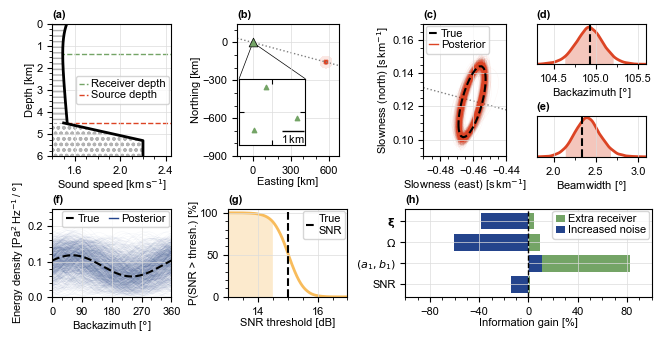

In [ ]:
#________ CREATE FIGURE ________#

#__ Figure __
fig = plt.figure(
    figsize   = (6.5, 3.25),
    facecolor = 'white',
    layout    = 'constrained'
)

#__ Axes __
gs  = GridSpec(
    figure = fig,
    nrows  = 2,
    ncols  = 4,
    height_ratios = [3, 2]
)
gs_pdf = gs[0,3].subgridspec(nrows=2, ncols=1)
axs = [
    # First row
    fig.add_subplot(gs[0,0]),                   # axs[0] is the sound-speed profile          (a)
    fig.add_subplot(gs[0,1], aspect='equal'),   # axs[1] is the source-receiver geometry     (b)
    fig.add_subplot(gs[0,2], aspect='equal'),   # axs[2] is the inverted signal              (c)
    fig.add_subplot(gs_pdf[0]),                 # axs[3] is the pdf of backazimuth           (d)
    fig.add_subplot(gs_pdf[1]),                 # axs[4] is the pdf of backazimuth beamwidth (e)
    # Second row
    fig.add_subplot(gs[1,0]),                   # axs[5] is the noise field                  (f)
    fig.add_subplot(gs[1,1]),                   # axs[6] is the SNR                          (g)
    fig.add_subplot(gs[1,2:4]),                 # axs[7] is information gain                 (h)
]

#__ Create inset axes __
ax_in = axs[1].inset_axes([0.02, 0.01, 0.65, 0.65], zorder=5) # [x0, y0, width, height]
ax_in.set_facecolor('white')
ax_in.set_aspect('equal')

#__ Labels __
for ax, xlab, ylab in zip(axs,
    [
        r"Sound speed [km$\,$s$^{-1}$]", r"Easting [km]", r"Slowness (east) [s$\,$km$^{-1}$]",
        r"Backazimuth [$\degree$]", r"Beamwidth [$\degree$]",
        r"Backazimuth [$\degree$]", r"SNR threshold [dB]", r"Information gain [%]"
    ],
    [
        r"Depth [km]", r"Northing [km]", r"Slowness (north) [s$\,$km$^{-1}$]",
        None, None,
        r"Energy density\n[mPa$^2$$\,$Hz$^{-1}$$\,$/$\,\degree$]", r"P(SNR > thresh.) [%]", None
    ]
):
    if (xlab is not None): ax.set_xlabel(xlab, fontsize=small, labelpad=1.0)
    if (ylab is not None): ax.set_ylabel(ylab, fontsize=small, labelpad=1.0)

#__ Ticks __
for ax, xlims, ylims, xticks, yticks in zip(axs,
    [
        (1.4,2.45), (-125,680), (-0.49,-0.44),
        (104.3,105.6), (1.8,3.1),
        (0,360), (13,17), (-100,100)
    ],
    [
        (6.0,0.0), (-900,150), (0.09,0.17),
        (0.0,2.7), (0.0,2.7),
        (0,0.25), (0,105), None
    ],
    [
        (0.4,0.1), (300,100), (0.02,0.005),
        (0.5,0.25), (0.5,0.25),
        (90,30), (2,0.5), (40,10)
    ],
    [
        (1.0,0.25), (300,100), (0.02,0.005),
        None, None,
        (0.1,0.02), (50,10), None
    ]
):
    if xlims is not None:
        ax.set_xlim(*xlims)
    if ylims is not None:
        ax.set_ylim(*ylims)
    if xticks is not None:
        ax.xaxis.set_major_locator(ticker.MultipleLocator(xticks[0]))
        ax.xaxis.set_minor_locator(ticker.MultipleLocator(xticks[1]))
    else: ax.set_xticks([])
    if yticks is not None:
        ax.yaxis.set_major_locator(ticker.MultipleLocator(yticks[0]))
        ax.yaxis.set_minor_locator(ticker.MultipleLocator(yticks[1]))
    else: ax.set_yticks([])
    ax.tick_params(labelsize=small)
    ax.grid(color='gainsboro', linewidth=0.5)

#__ Ticks (inset) __
ax_in.set_xlim(-1.5,1.5)
ax_in.set_ylim(-1.5,1.5)
ax_in.set_xticks([0])
ax_in.set_yticks([0])
ax_in.tick_params(
    which='both', direction='in',
    top=True, right=True,
    labelbottom=False, labelleft=False
)
ax_in.grid(color='gainsboro', linewidth=0.5)

#________ PLOT: SOUND-SPEED PROFILE ________#

#__ Water column __
axs[0].fill_betweenx(
    1e-3*z, 0.0, 1e-3*c_z,
    facecolor='none', edgecolor='0.7',
    hatch='---', linewidth=0.0, zorder=0.9
)
axs[0].plot(1e-3*c_z, 1e-3*z, color='k', linewidth=2.0, zorder=2)

#__ Sediment column __
axs[0].fill_betweenx(
    1e-3*z_sed, 0.0, 1e-3*c_sed,
    facecolor='none', edgecolor='0.7',
    hatch='ooo', linewidth=0.0, zorder=0.9
)
axs[0].plot(1e-3*c_sed, 1e-3*z_sed, color='k', lw=2.0, zorder=2)

#__ Opaque white base (hides anything with lower zorder) __
for zz, cc in [(z, c_z), (z_sed, c_sed)]:
    axs[0].fill_betweenx(1e-3*zz, 0.0, 1e-3*cc, facecolor='white', edgecolor='none', zorder=0.8)

#__ Receiver/source depths __
axs[0].axhline(1e-3*zr, ls='--', color=theme[1], lw=1.0, zorder=0.5, label='Receiver depth')
axs[0].axhline(1e-3*z_max, ls='--', color=theme[0], lw=1.0, zorder=0.5, label='Source depth')

#__ Legend __
axs[0].legend(fontsize=small, loc='center right', labelspacing=0.1,
    handlelength=0.8, handleheight=0.6, handletextpad=0.3,
    borderpad=0.3, borderaxespad=0.2
)

#________ PLOT: SOURCE-RECEIVER GEOMETRY ________#

#__ Plot source energy __
axs[1].contourf(
    1e-3*Xs, 1e-3*Ys, E_src,
    levels=np.linspace(0.02,0.5,5), cmap=cmap0, extend='max',
    zorder=1
)

#__ Plot array location __
axs[1].scatter(
    0, 0,
    c=theme[1], s=40, marker='^', edgecolors='k', linewidths=0.5,
    zorder=2
)

#__ Plot receivers __
ax_in.scatter(
    1e-3*x[:,0], 1e-3*x[:,1],
    c=theme[1], s=10, marker='^',
    zorder=1
)

#__ Scale bar (inset) __
scalebar = AnchoredSizeBar(
    ax_in.transData,
    1.0, r"1$\,$km",
    loc='lower right',
    pad=0.0, borderpad=0.0, sep=1,
    color='k', frameon=False,
    size_vertical=0.02,
    fontproperties=fm.FontProperties(size=small)
)
ax_in.add_artist(scalebar)

#__ Plot reference line __
axs[1].axline(
    (0,0), (np.sin(np.radians(105)), np.cos(np.radians(105))),
    ls=':', color='gray', lw=1.0,
    zorder=1
)

#__ Connector lines: inset top corners -> array triangle __
for corner in [(0.0, 1.0), (1.0, 1.0)]:
    axs[1].add_artist(ConnectionPatch(
        xyA=corner, coordsA=ax_in.transAxes,      # inset corner, in inset axes fraction
        xyB=(0.0, 0.0), coordsB=axs[1].transData, # array position, in panel (b) data
        color='k', lw=0.5, zorder=1
    ))

#________ SIGNAL FIELD ________#

#__ Plot reference line __
axs[2].axline(
    (0,0), (np.sin(np.radians(105)), np.cos(np.radians(105))),
    ls=':', color='gray', lw=1.0,
    zorder=1
)

#__ True __
axs[2].contour(
    1e3*gx, 1e3*gy, density_true[0], levels=[0.5],
    colors='k', linewidths=1.5, linestyles='--',
    zorder=2
)
handles = [
    Line2D([], [], color='k', ls='--', lw=1.5, label='True'),
    Line2D([], [], color=theme[0], lw=1.0, label='Posterior'),
]
axs[2].legend(handles=handles, fontsize=small, loc='upper left', labelspacing=0.1,
    handlelength=0.8, handleheight=0.6, handletextpad=0.3,
    borderpad=0.3, borderaxespad=0.2)

#__ Estimates __
for i in range(1000):
    axs[2].contour(
        1e3*gx, 1e3*gy, density[i], levels=[0.5],
        colors=theme[0], linewidths=0.3, alpha=0.05,
        zorder=1
    )

#________ PROBABILITY DENSITY FUNCTIONS ________#

#__ Backazimuth __
axs[3].plot(
    (p_az_vec-180)%360, p_az,
    color=theme[0], lw=2.0,
    zorder=1
)
axs[3].axvline((xi_circ_true[0,1]-180)%360, ls='--', color='k', lw=1.5, zorder=2)
in_ci = np.logical_and(p_az_vec>=baz_05, p_az_vec<=baz_95)
axs[3].fill_between((p_az_vec[in_ci]-180)%360, p_az[in_ci], color=theme[0], alpha=0.3, lw=0, zorder=1)

#__ Backazimuth beamwidth __
axs[4].plot(
    p_bw_vec, p_bw,
    color=theme[0], lw=2.0,
    zorder=1
)
axs[4].axvline(sigma_circ_true[0,1], ls='--', color='k', lw=1.5, zorder=2)
in_ci = np.logical_and(p_bw_vec>=bw_05, p_bw_vec<=bw_95)
axs[4].fill_between(p_bw_vec[in_ci], p_bw[in_ci], color=theme[0], alpha=0.3, lw=0, zorder=1)

#________ NOISE FIELD ________#

#__ True model __
axs[5].plot(
    baz, 1e-6*rho_true[0] * 10**(75/10) * np.pi/180,
    color='k', lw=1.5, ls='--',
    zorder=2
)
handles = [
    Line2D([], [], color='k', ls='--', lw=1.5, label='True'),
    Line2D([], [], color=theme[2], lw=1.0, label='Posterior'),
]
axs[5].legend(handles=handles, ncols=2, fontsize=small, loc='upper right', labelspacing=0.1,
    handlelength=0.8, handleheight=0.6, handletextpad=0.3,
    borderpad=0.3, borderaxespad=0.2, columnspacing=0.8)

#__ Estimates __
for i in range(1000):
    if np.any(rho[i] < 0): continue
    axs[5].plot(
        baz, 1e-6*rho[i] * 10**(m[i,6]/10) * np.pi/180,
        color=theme[2], lw=0.3, alpha=0.05,
        zorder=1
    )

#________ SNR ________#

axs[6].plot(
    pcum_snr_vec, 100*pcum_snr,
    color=theme[3], lw=2.0,
    zorder=1
)
axs[6].axvline(15, ls='--', color='k', lw=1.5, zorder=2)
in_ci = np.logical_and(pcum_snr_vec>=0., pcum_snr_vec<=snr_90)
axs[6].fill_between(pcum_snr_vec[in_ci], 100*pcum_snr[in_ci], color=theme[3], alpha=0.3, lw=0, zorder=1)

#__ Legend __
handles = [
    Line2D([], [], color='k', ls='--', lw=1.5, label='True\nSNR')
]
axs[6].legend(handles=handles, fontsize=small, loc='upper right', labelspacing=0.3,
    handlelength=0.8, handleheight=0.6, handletextpad=0.3,
    borderpad=0.3, borderaxespad=0.2)

#________ INFORMATION GAIN ________#

#__ Labels __
y      = np.arange(4)[::-1]
labels = [r"$\mathbf{\xi}$", r"$\Omega$", r"$\left(a_1, b_1\right)$", r"SNR"]
axs[7].set_yticks(y, labels)

#__ Extra receiver __
axs[7].barh(
    y, rel_IG_rec,
    color=theme[1], label="Extra receiver",
    zorder=1
)

#__ Noise increase __
axs[7].barh(
    y, rel_IG_noisy,
    color=theme[2], label="Increased noise",
    zorder=1
)

#__ Plot neutral __
axs[7].axvline(0, c='k', ls='--', lw=1.0, zorder=2)

#__ Legend __
axs[7].legend(fontsize=small, loc='upper right', labelspacing=0.1,
    handlelength=0.8, handleheight=0.6, handletextpad=0.3,
    borderpad=0.3, borderaxespad=0.2)

#__ Panel labels, in reading order __
for ax, label in zip(axs, ['(a)', '(b)', '(c)', '(d)', '(e)', '(f)', '(g)', '(h)']):
    ax.set_title(label, loc='left', fontsize=small, fontweight='bold', pad=4)

#__ Spacing __
fig.get_layout_engine().set(h_pad=0.01, hspace=0.0)

#__ Show figure __
fig.show()
fig.savefig('./data/figures/Figure_1.pdf', dpi=300, bbox_inches='tight')

## Real data

In [ ]:
#__ Read data __
data = np.load('./data/hukkakero/IS37_hukkakero_2016-08-19.npz')
u_t = data['u_t']  # Waveform data     [Pa] (receiver, time)
t   = data['t']    # Lapse time vector [s]  (time,)
x   = data['x']    # Receiver location [m]  (receiver, direction)

#__ Select signal and noise windows __
T_w   = 20.0                                   # Window half-width [s]
t_w_s = 1360                                   # Signal-window central time [s]
t_w_n = [750, 800, 850, 900, 950, 1000, 1050]  # Noise-window central times [s]

#__ Masks __
win_s = (np.abs(t - t_w_s) < T_w)  # Signal window mask (time,)
win_n = [
    (np.abs(t - t_w_ni) < T_w)     # Noise window mask (time,)
    for t_w_ni in t_w_n
]

#__ Read results __
m = np.loadtxt(f"./models/hukkakero/model-samples_iteration-30000.txt")

#__ Unpack results __
w_s   = m[:,0]
xi    = m[:,1:3]
sigma = m[:,3:5]
corr  = m[:,5]
alpha = m[:,6:8]
w_n1  = m[:,8]
w_n2  = m[:,9]
a     = m[:,10:12]
b     = m[:,12:14]

#__ Rotate results __
wd, mean, xi_circ, mean_circ, sigma_circ, wd_circ = density_params(xi, sigma, corr[:,None], alpha)
# p = density_function(xi, sigma, corr, alpha)

#__ Noise field __
baz = np.linspace(0, 360, 360)
rho = harmonic2D_density(baz, a, b)
rho = rho[np.all(rho)]

#__ Marginal statistics __
stats = MarginalStats(m)
stats_circ = MarginalStats(np.hstack((xi_circ, sigma_circ, wd_circ)))
p_ws, ws_vec = stats.probability_density(i=0)
p_wn1, wn1_vec = stats.probability_density(i=8)
p_wn2, wn2_vec = stats.probability_density(i=9)
ws_05, ws_95 = stats.credible_interval(90, [0])
wn1_05, wn1_95 = stats.credible_interval(90, [8])
wn2_05, wn2_95 = stats.credible_interval(90, [9])

#__ 2D kernel density on a grid __
def kde_2d(samples, npts=200, bounds=None, pad=0.1):
    """
    Input
    -----
    samples : ``numpy.ndarray``
        (sample, 2)

    bounds : ``numpy.ndarray`` (optional)
        [[lo0, hi0], [lo1, hi1]]; sample range padded by `pad` if None

    Output
    ------
    density : ``numpy.ndarray``
        (npts, npts), indexed [dim0, dim1]

    vecs : ``tuple`` of ``numpy.ndarray``
        Grid vectors for each dimension
    """
    if bounds is None:
        lo, hi = samples.min(axis=0), samples.max(axis=0)
        bounds = np.stack([lo - pad*(hi-lo), hi + pad*(hi-lo)], axis=1)
    v0 = np.linspace(*bounds[0], npts)
    v1 = np.linspace(*bounds[1], npts)
    g0, g1 = np.meshgrid(v0, v1, indexing='ij')
    density = gaussian_kde(samples.T)(np.vstack([g0.ravel(), g1.ravel()])).reshape(npts, npts)
    return density, (v0, v1)
density, (v0, v1) = kde_2d(np.hstack((xi_circ[:,[1]],wd_circ[:,[1]])))

#__ Read: Signal + noise __
out = read_txt("./data/hukkakero/signal_topophone2.txt")
freq_Hz   = out[0]  # Frequency vector         [Hz]       (frequency)
x         = out[1]  # Receiver position        [m]        (receiver, direction)
Gamma_obs = out[2]  # Array-covariance matrix  [Pa2.Hz-1] (frequency, receiver, receiver)
N_obs     = out[3]  # Independent observations
freq      = 2 * np.pi * freq_Hz

#__ Beamforming __
def slowness_grid(p_bounds, dp):
    vecs = [np.linspace(p_min, p_max, int(round((p_max-p_min)/dp))+1) for (p_min, p_max) in p_bounds]
    grid = np.meshgrid(*vecs, indexing='ij')
    return np.stack([g.ravel() for g in grid], axis=-1), vecs
def bartlett_power(
    Gamma        : np.ndarray,
    x            : np.ndarray,
    freq         : np.ndarray,
    p_bounds     : list,
    dp           : float,
    normalise    : bool = False,
    exclude_diag : bool = False,
    chunk        : int  = 4096
):
    """
    Bartlett (conventional, delay-and-sum) beam power from an array-covariance matrix.
 
    Assumes Gamma[f, j, k] = E[u_j u_k^*] with NumPy's FFT sign convention, for which a
    plane wave of slowness p has u_j ~ exp(-i w p.x_j). The steering vector is
    a_j(p) = exp(-i w p.x_j) and B(p) = a^H Gamma a / N^2.
 
    Input
    -----
    Gamma : ``numpy.ndarray``
        Array-covariance matrix [Pa2.Hz-1]
        (frequency, receiver, receiver)
 
    x : ``numpy.ndarray``
        Receiver position [m]
        (receiver, direction)
 
    freq : ``numpy.ndarray``
        Angular frequency [rad.s-1]
        (frequency,)
 
    p_bounds : ``list``
        (Minimum, maximum) slowness to search in each direction [s.m-1]
 
    dp : ``float``
        Slowness search interval [s.m-1]
 
    normalise : ``bool`` (default ``False``)
        Divide by the mean auto-power, so B lies in [0, 1] (comparable across frequencies)
 
    exclude_diag : ``bool`` (default ``False``)
        Use cross-terms only (j != k), removing the incoherent-noise floor
 
    Output
    ------
    B : ``numpy.ndarray``
        Beam power [Pa2.Hz-1, or dimensionless if normalised]
        (frequency, *slowness grid)
 
    vecs : ``list`` of ``numpy.ndarray``
        Slowness vector in each direction [s.m-1]
    """
 
    #__ Slowness grid and travel times __
    p, vecs = slowness_grid(p_bounds, dp)              # (slowness, direction)
    tau     = p @ x.T                                  # (slowness, receiver)
    N       = x.shape[0]
 
    #__ Optionally drop the auto-power terms __
    G = Gamma.copy()
    if exclude_diag:
        G[:, np.arange(N), np.arange(N)] = 0.0
 
    #__ Beam power, chunked over slowness to bound memory __
    B = np.empty((len(freq), len(p)))
    for s0 in range(0, len(p), chunk):
        a = np.exp(-1j * freq[:,None,None] * tau[None,s0:s0+chunk,:])   # (freq, slowness, receiver)
        B[:, s0:s0+chunk] = np.einsum('fsj,fjk,fsk->fs', a.conj(), G, a).real
 
    #__ Normalise __
    if exclude_diag: B /= N*(N-1)
    else:            B /= N**2
    if normalise:
        auto = np.trace(Gamma, axis1=1, axis2=2).real / N             # mean auto-power (frequency,)
        B /= auto[:, None]
 
    #__ Return output __
    return B.reshape(len(freq), *[len(v) for v in vecs]), vecs
B, (px, py) = bartlett_power(
    Gamma_obs, x, freq,                        # freq in rad/s, as you've defined it
    p_bounds=[(-4.5e-3, 4.5e-3)]*2, dp=2e-5,
    normalise=True
)
B_band = B.mean(axis=0)

/tmp/ipykernel_2956/1876386110.py:126: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


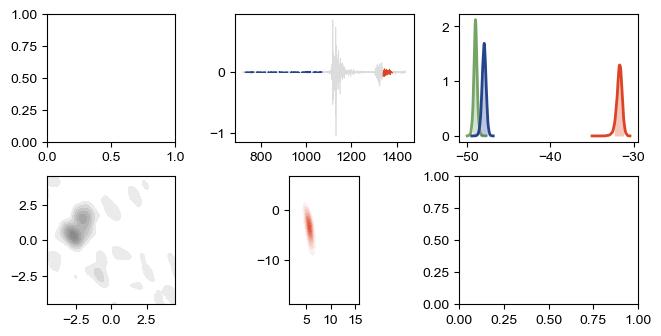

In [ ]:
#________ CREATE FIGURE ________#

#__ Figure __
fig = plt.figure(
    figsize = (6.5,3.25),
    facecolor='white',
    layout='constrained'
)

#__ Axes __
gs = GridSpec(
    figure = fig,
    nrows = 2,
    ncols = 3
)
axs = [
    fig.add_subplot(gs[0,0], aspect='equal'),
    fig.add_subplot(gs[0,1]),
    fig.add_subplot(gs[0,2]),
    fig.add_subplot(gs[1,0], aspect='equal'),
    fig.add_subplot(gs[1,1], aspect='equal'),
    fig.add_subplot(gs[1,2])
]

#__ Labels __
for ax, xlab, ylab in zip(axs,
    [
    ],
    [
    ]
):
    if (xlab is not None): ax.set_xlabel(xlab, fontsize=small, labelpad=1.0)
    if (ylab is not None): ax.set_ylabel(ylab, fontsize=small, labelpad=1.0)

#__ Ticks __
for ax, xlims, ylims, xticks, yticks in zip(axs,
    [
    ],
    [
    ],
    [
    ],
    [
    ]
):
    if xlims is not None:
        ax.set_xlim(*xlims)
    if ylims is not None:
        ax.set_ylim(*ylims)
    if xticks is not None:
        ax.xaxis.set_major_locator(ticker.MultipleLocator(xticks[0]))
        ax.xaxis.set_minor_locator(ticker.MultipleLocator(xticks[1]))
    else: ax.set_xticks([])
    if yticks is not None:
        ax.yaxis.set_major_locator(ticker.MultipleLocator(yticks[0]))
        ax.yaxis.set_minor_locator(ticker.MultipleLocator(yticks[1]))
    else: ax.set_yticks([])
    ax.tick_params(labelsize=small)
    ax.grid(color='gainsboro', linewidth=0.5)

#________ PLOT: RECEIVER GEOMETRY ________#

#________ PLOT: WAVEFORM ________#

#__ Plot waveform __
axs[1].plot(t, u_t[0], lw=0.5, c='gainsboro', zorder=1)

#__ Plot signal __
axs[1].plot(t[win_s], u_t[0,win_s], lw=0.5, c=theme[0], zorder=2, label="Signal window")

#__ PLot noise __
for i, win_ni in enumerate(win_n):
    axs[1].plot(t[win_ni], u_t[0,win_ni], lw=0.5, c=theme[2], zorder=2, label="Noise window" if i == 0 else "_nolegend_")

#________ PLOT: SNR ________#

#__ Signal __
axs[2].plot(
    ws_vec, p_ws,
    color=theme[0], lw=2.0,
    zorder=1
)
in_ci = np.logical_and(ws_vec>=ws_05, ws_vec<=ws_95)
axs[2].fill_between(ws_vec[in_ci], p_ws[in_ci], color=theme[0], alpha=0.3, lw=0, zorder=1)

#__ Self-noise __
axs[2].plot(
    wn1_vec, p_wn1,
    color=theme[1], lw=2.0,
    zorder=1
)
in_ci = np.logical_and(wn1_vec>=wn1_05, wn1_vec<=wn1_95)
axs[2].fill_between(wn1_vec[in_ci], p_wn1[in_ci], color=theme[1], alpha=0.3, lw=0, zorder=1)

#__ Environament noise __
axs[2].plot(
    wn2_vec, p_wn2,
    color=theme[2], lw=2.0,
    zorder=1
)
in_ci = np.logical_and(wn2_vec>=wn2_05, wn2_vec<=wn2_95)
axs[2].fill_between(wn2_vec[in_ci], p_wn2[in_ci], color=theme[2], alpha=0.3, lw=0, zorder=1)

#________ PLOT: BEAMFORMING & SIGNAL ________#

#__ Beamforming __
axs[3].contourf(
    1e3*px, 1e3*py, B_band.T,
    cmap='cmc.grayC_r', vmin=0.1, vmax=0.8, levels=8,
    zorder=1
)

#________ PLOT: SIGNAL MARGINAL ________#

#__ Cross-plot __
axs[4].contourf(
    (v0-180)%360-110, v1, density,
    cmap=cmap0, vmin=0.01, levels=10,
    zorder=1
)

#________ PLOT: NOISE FIELD ________#

#__ Show figure __
fig.show()

## Supplementary